In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df =  pd.read_csv(url)

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [6]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income','number_of_courses_viewed', 'interaction_count','lead_score']

##filling missing value

df[numerical] = df[numerical].fillna(0.0)
df[categorical] = df[categorical].fillna('NA')

In [7]:
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
y_train = df_train.converted
y_val = df_val.converted
y_test = df_test.converted

del df_train['converted']
del df_val['converted']
del df_test['converted']

### Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
Use the training dataset for that
If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

lead_score
number_of_courses_viewed
interaction_count
annual_income

In [9]:
from sklearn.metrics import roc_auc_score

for col in df[numerical]:
    auc = round(roc_auc_score(y_train, df_train[col]),4)
    print(f' {col} --> {auc}')

 annual_income --> 0.6082
 number_of_courses_viewed --> 0.723
 interaction_count --> 0.7649
 lead_score --> 0.7882


### Question 2: Training the model

Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
What's the AUC of this model on the validation dataset? (round to 3 digits)

0.532
0.632
0.732
0.832

In [10]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

features = categorical + numerical
# Prepare the features
train_dict = df_train[features].to_dict(orient='records')
val_dict = df_val[features].to_dict(orient='records')

# One-hot encoding
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

# Train the model
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)
model.fit(X_train, y_train)

# Predict probabilities for the positive class
y_pred = model.predict_proba(X_val)[:, 1]

# Calculate validation AUC
auc = roc_auc_score(y_val, y_pred)

print(round(auc, 3))

0.732


### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01

For each threshold, compute precision and recall

Plot them
At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

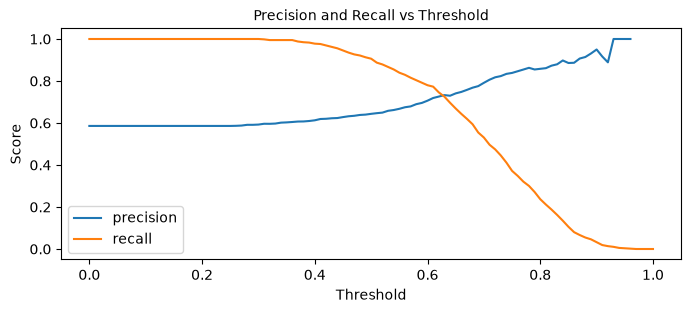

threshold       0.630000
tp            425.000000
fp            155.000000
fn            161.000000
tn            259.000000
precision       0.732759
recall          0.725256
difference      0.007503
Name: 63, dtype: float64


In [11]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

# Handle division by zero by assigning NaN
df_scores['precision'] = (
    df_scores['tp'] /
    (df_scores['tp'] + df_scores['fp']).replace(0, np.nan)
)

df_scores['recall'] = (
    df_scores['tp'] /
    (df_scores['tp'] + df_scores['fn']).replace(0, np.nan)
)

# Plot precision and recall
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 3))
plt.title('Precision and Recall vs Threshold', fontsize = 10)
plt.plot(df_scores['threshold'], df_scores['precision'], label='precision')
plt.plot(df_scores['threshold'], df_scores['recall'], label='recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

# Calculate absolute difference
df_scores['difference'] = abs(
    df_scores['precision'] - df_scores['recall']
)

# Exclude rows where both metrics are zero
valid = df_scores[
    ~(
        (df_scores['precision'] == 0) &
        (df_scores['recall'] == 0)
    )
].dropna(subset=['difference'])

# Find the threshold with the smallest difference
best = valid.loc[valid['difference'].idxmin()]

print(best)


### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$ F1 = \frac{2⋅P⋅R}{P+R} $$

Where 
P
 is precision and 
R
 is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01
At which threshold F1 is maximal?


In [12]:
df_scores['F1_Score'] = (2 *  df_scores['precision'] * df_scores['recall'])/( df_scores['precision'] + df_scores['recall'])

In [13]:
df_scores[df_scores['F1_Score'] == df_scores['F1_Score'].max()]

,threshold,tp,fp,fn,tn,precision,recall,difference,F1_Score
41,0.41,572,352,14,62,0.619048,0.976109,0.357062,0.757616


### Question 5: 5-Fold CV

Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)
Iterate over different folds of df_full_train
Split the data into train and validation
Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
Use AUC to evaluate the model on validation
How large is standard deviation of the scores across different folds?

In [14]:
def train(df_train, y_train, C=1.0,):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [15]:
from sklearn.model_selection import KFold
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
   df_train = df_full_train.iloc[train_idx]
   df_val = df_full_train.iloc[val_idx]
   y_train = df_train.converted
   y_val = df_val.converted
   dv, model = train(df_train, y_train)
   y_pred = predict(df_val, dv, model)
   auc = roc_auc_score(y_val, y_pred)
   scores.append(auc)

print('Standard deviation:', np.std(scores).round(3))

Standard deviation: 0.007


### Question 6: Hyperparameter Tuning
Now let's use 5-Fold cross-validation to find the best parameter C

Iterate over the following C values: $[0.000001, 0.001, 1]$

Initialize KFold with the same parameters as previously
Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).
Which C leads to the best mean ROC AUC?

0.000001

0.001

1
If you have ties, select the score with the lowest std. If you still have ties, select the smallest C

In [16]:
from tqdm.auto import tqdm
n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted
        y_val = df_val.converted

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
